# Comparing centrelines generated by different methods


We generate polylines in various ways: by contracting a point cloud, by computing a maximum spanning tree of clearance in a voxset, but moving iteratively in a mesh. 

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from base.mst_centreline import return_MST_centrelines
from base.lbc_centreline import return_LBC_centreline
from base.frechet_dist import frdist
from base.refine_centreline import refine


from stl import mesh

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [4]:
#CONDUIT_NAME = "straight_cylinder_L8_R1_stochastic"
#CONDUIT_NAME = "sinuous_D5_r_1"
CONDUIT_NAME = "straight_cylinder_L10_R1"



First, we return the Laplacian-contraction based algorithm to find a centreline using several dictionaries of arguments. 

In [11]:
ct_args = dict(keep=False, keep_centreline=False, centreline_down_sample= 0.2)
lbc_args = dict(init_attraction = 2, init_contraction = 0.5, down_sample = 0.2)

centreline_filepath = f"./tests/centrelines/LBC_{CONDUIT_NAME}_centreline.txt"

test_lbc = return_LBC_centreline(mesh_filepath = f"./tests/meshes/{CONDUIT_NAME}.stl",
                                 adjacent_triangles_filepath=f"./tests/meshes/{CONDUIT_NAME}_adjacent_triangles.txt",
                                 ct_args= ct_args,
                                 lbc_args= lbc_args)

knn search complete and neighbouring triangles found in 126.8734s (347858 triangle neighbour sets.)
read file in 0.0000s


2025-03-07 08:40:27,308 - PCD #points: 2000


contracted file in 1.1329s


Current volume ratio 1.0. Contraction weights 354.0875757639706. Attraction weights 4.278736902213599. Progress LBC:  12025-03-07 08:40:28,747 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 354.0875757639706. Attraction weights 4.278736902213599. Progress LBC:  1

Contraction is Done.
extracted skeleton in 1.4707s
downsampled the centreline cloud in 0.0000s
there were 0 connected components.
found largest component in 0.0000s
computed minimum spanning tree in 0.0163s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
found ring 1 with 715 points.
found ring 2 with 715 points.


computed shortest path in  0.1911s


In [12]:
test_mst = return_MST_centrelines(f"./tests/meshes/{CONDUIT_NAME}.stl", 
                                  f"./tests/voxsets/{CONDUIT_NAME}.vxl", 
                                  delta=200)

delta:  200


Read 'C:\Users\tangr\GitHub\network_processing_tools\tests\voxsets\straight_cylinder_L10_R1.vxl': 174,644 vertices and 3,722 grid points,
Added edges in 3.2 sec.


found ring 1 with 715 points.
found ring 2 with 715 points.
inlet coordinates:  [-4.9938857e+03  1.1527327e+00  1.4374228e+01]
outlet coordinates:  [4.9949365e+03 4.1379075e+00 5.0646100e+00]


Computed maximum spanning tree for clearance in 0.1 sec.
Computed path in maximum spanning tree in 0.0 sec.
2025-03-07 08:42:43,908 - creating ACAD_COLOR dictionary
2025-03-07 08:42:43,908 - creating ACAD_GROUP dictionary
2025-03-07 08:42:43,908 - creating ACAD_LAYOUT dictionary
2025-03-07 08:42:43,908 - creating ACAD_MATERIAL dictionary
2025-03-07 08:42:43,922 - creating ACAD_MLEADERSTYLE dictionary
2025-03-07 08:42:43,922 - creating ACAD_MLINESTYLE dictionary
2025-03-07 08:42:43,922 - creating ACAD_PLOTSETTINGS dictionary
2025-03-07 08:42:43,929 - creating ACAD_PLOTSTYLENAME dictionary
2025-03-07 08:42:43,932 - creating ACAD_SCALELIST dictionary
2025-03-07 08:42:43,932 - creating ACAD_TABLESTYLE dictionary
2025-03-07 08:42:43,932 - creating ACAD_VISUALSTYLE dictionary
2025-03-07 08:42:43,980 - did not write header var $INTERFEREOBJVS, value is None.
2025-03-07 08:42:43,980 - did not write header var $INTERFEREVPVS, value is None.
2025-03-07 08:42:44,053 - creating ACAD_COLOR dictiona

Added edges in 0.1 sec.
Computed shortest path in 0.0 sec.
[array([-4.9939e+03,  1.2000e+00,  1.4400e+01], dtype=float32), array([-4800,     0,     0]), array([-4600,     0,     0]), array([-4400,     0,     0]), array([-4200,     0,     0]), array([-4000,     0,     0]), array([-3800,     0,     0]), array([-3600,     0,     0]), array([-3400,     0,     0]), array([-3200,     0,     0]), array([-3000,     0,     0]), array([-2800,     0,     0]), array([-2600,     0,     0]), array([-2400,     0,     0]), array([-2200,     0,     0]), array([-2000,     0,     0]), array([-1800,     0,     0]), array([-1600,     0,     0]), array([-1400,     0,     0]), array([-1200,     0,     0]), array([-1000,     0,     0]), array([-800,    0,    0]), array([-600,    0,    0]), array([-400,    0,    0]), array([-200,    0,    0]), array([0, 0, 0]), array([200,   0,   0]), array([400,   0,   0]), array([600,   0,   0]), array([800,   0,   0]), array([1000,    0,    0]), array([1200,    0,    0]), a

2025-03-07 08:42:44,056 - creating ACAD_LAYOUT dictionary
2025-03-07 08:42:44,057 - creating ACAD_MATERIAL dictionary
2025-03-07 08:42:44,058 - creating ACAD_MLEADERSTYLE dictionary
2025-03-07 08:42:44,061 - creating ACAD_MLINESTYLE dictionary
2025-03-07 08:42:44,063 - creating ACAD_PLOTSETTINGS dictionary
2025-03-07 08:42:44,067 - creating ACAD_PLOTSTYLENAME dictionary
2025-03-07 08:42:44,067 - creating ACAD_SCALELIST dictionary
2025-03-07 08:42:44,067 - creating ACAD_TABLESTYLE dictionary
2025-03-07 08:42:44,073 - creating ACAD_VISUALSTYLE dictionary
2025-03-07 08:42:44,106 - did not write header var $INTERFEREOBJVS, value is None.
2025-03-07 08:42:44,109 - did not write header var $INTERFEREVPVS, value is None.
Polyline has 51 vertices
Simplified polyline has 2 vertices
2025-03-07 08:42:54,524 - creating ACAD_COLOR dictionary
2025-03-07 08:42:54,524 - creating ACAD_GROUP dictionary
2025-03-07 08:42:54,524 - creating ACAD_LAYOUT dictionary
2025-03-07 08:42:54,524 - creating ACAD_MATE

simplified polyline has fewer than 2 vertices. Impossible to simplify further.


In [13]:
mesh_filepath = f"./tests/meshes/{CONDUIT_NAME}.stl"

In [14]:
meshdata = mesh.Mesh.from_file(mesh_filepath)

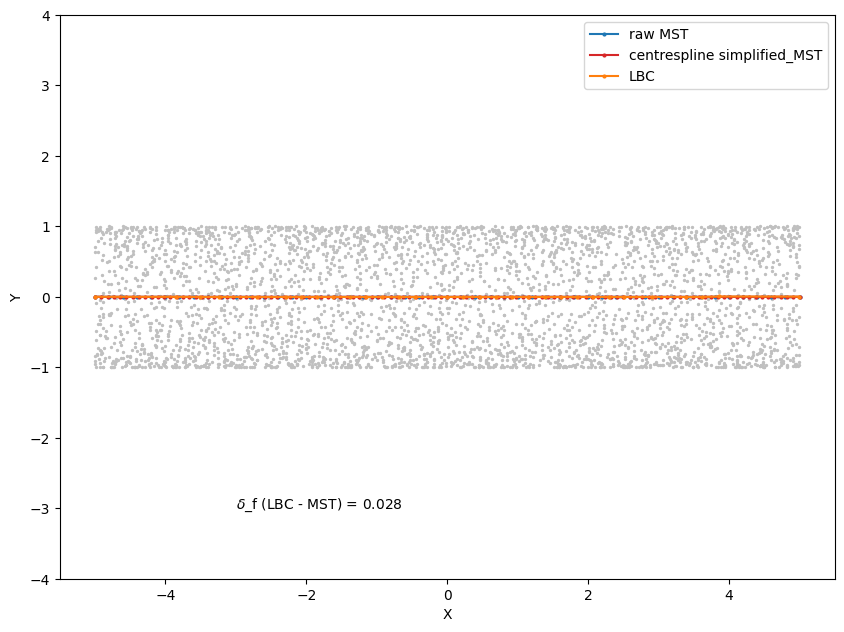

In [15]:
fig, ax = plt.subplots(figsize = (10,10))

ax.plot(*test_mst["raw"].T[[0,1]], "-o", color = "C0", markersize=2, label="raw MST")
ax.plot(*test_mst["centerspline_direct"].T[[0,1]], "-o", color = "C3", markersize= 2, label= "centrespline simplified_MST")
ax.plot(*test_lbc["centreline"].T[[0,1]], "-o", color = "C1", markersize= 2, label = "LBC")
#ax.plot(*expected_ct.T[[0,1]], "-o", color = "C2", markersize= 2, label="expected")

ax.scatter(*meshdata.centroids.T[[0,1],::100], color = "silver", s=2, zorder = -100)
ax.set_aspect("equal")
ax.set_ylim(-4,4)
ax.legend()

p1 = refine( test_lbc["centreline"], 200)
p2 = refine( test_mst["raw"], 200)
frechet_dist = frdist(p1,p2)
ax.text(-3,-3, f"$\delta$_f (LBC - MST) = {frechet_dist:.3f}")

ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.savefig(f"./tests/outputs/CoC_{CONDUIT_NAME}_plan.png", dpi = 300)
plt.show()

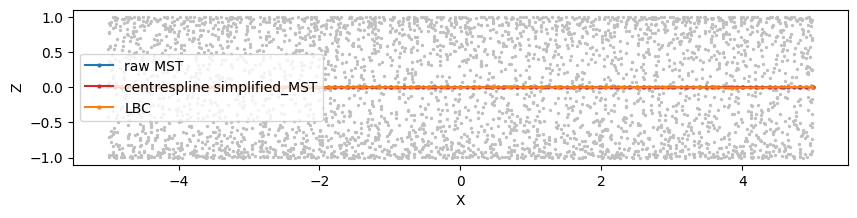

In [16]:
fig, ax = plt.subplots(figsize = (10,10))

ax.plot(*test_mst["raw"].T[[0,2]], "-o", color = "C0", markersize=2, label="raw MST")
ax.plot(*test_mst["centerspline_direct"].T[[0,2]], "-o", color = "C3", markersize= 2, label= "centrespline simplified_MST")
ax.plot(*test_lbc["centreline"].T[[0,2]], "-o", color = "C1", markersize= 2, label = "LBC")
#ax.plot(*expected_ct.T[[0,1]], "-o", color = "C2", markersize= 2, label="expected")

ax.scatter(*meshdata.centroids.T[[0,2],::100], color = "silver", s=2, zorder = -100)
ax.set_aspect("equal")
#ax.set_ylim(95,115)
ax.legend()

p1 = refine( test_lbc["centreline"], 200)
p2 = refine( test_mst["raw"], 200)
frechet_dist = frdist(p1,p2)
#ax.text(-90,40, f"$\delta$_f (LBC - MST) = {frechet_dist:.3f}")

ax.set_xlabel("X")
ax.set_ylabel("Z")
plt.savefig(f"./tests/outputs/CoC_{CONDUIT_NAME}_profile.png", dpi = 300)
plt.show()

In [24]:
expected_ct = np.zeros((2, 3))
expected_ct[:,0] = [-5,5]
expected_ct[:,2] = [1,1]

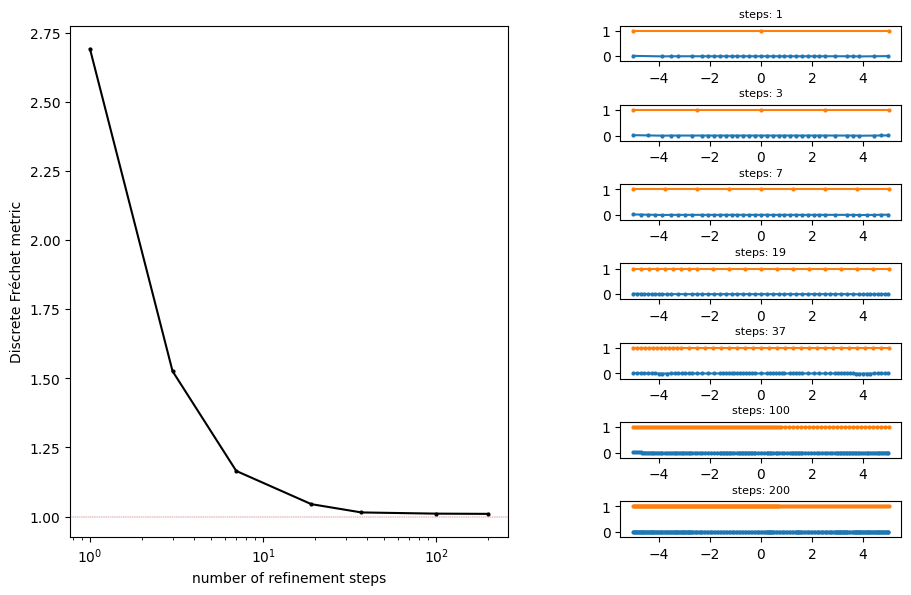

In [30]:
fig = plt.figure(figsize = (10,6))
frdists1, frdists2 = [],[]
nsteps = (1,3,7, 19, 37, 100, 200)
for c, nstep in enumerate(nsteps):

    p1 = refine( test_lbc["centreline"], nstep)
    p2 = refine( test_mst["raw"], nstep)
    q = refine( expected_ct, nstep)
    frdists1.append(frdist(p1, q))
    frdists2.append(frdist(p2, q))

    theax = fig.add_subplot(len(nsteps),2, 2*c+2)
    theax.plot(*p1[:, [0,2]].T, "-o", markersize = 2)
    theax.plot(*q[:, [0,2]].T, "-o", markersize = 2)

    theax.set_aspect("equal")
    theax.set_ylim(-0.2, 1.2)
    theax.set_title(f"steps: {nstep}", fontsize = 8)

ax = fig.add_subplot(121)
ax.semilogx(nsteps, frdists1, "-o", color = "k", markersize = 2)
#ax.semilogx(nsteps, frdists2, "-o")
ax.axhline(1,color = "firebrick", ls ="--", lw = 0.3)

ax.set_ylabel("Discrete Fréchet metric")
ax.set_xlabel("number of refinement steps")
plt.tight_layout()
plt.savefig("./tests/outputs/reparametrisation_frechet_metric.png", dpi = 300)